<a href="https://colab.research.google.com/github/samuelperez1232/prospectiva_analitica_datos/blob/main/parcial2_evergreen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Caso de Estudio	Gestión de Operaciones – EVERGREEN**

EVERGREEN es un conglomerado taiwanés que opera en diversas industrias a nivel global. Su principal empresa, Evergreen Marine Corporation, se especializa en el transporte marítimo de contenedores, gestionando una flota de más de 150 buques y ofreciendo servicios en 240 puertos alrededor del mundo.


La empresa está interesada en desarrollar un sistema de adaptación y aprendizaje que le permita proyectar, desde la gestión de sus riesgos, el valor potencial de Captura de Gases de Efecto Invernadero (GEI).  

Para la gestión de los riesgos, los impactos más frecuentes están asociados con el no embarque de contenedores a tiempo, por lo que la empresa quiere diseñar una serie de matrices de gestión e impacto que le permitan mitigar los riesgos asociados (Paramétros de Riesgo – Potenciales de Captura GEI).


Para la gestión de los riesgos, la empresa esta interesada en la evaluación de diferentes Matrices De Gestión, de modo que esto le permita la estimación diferenciada frente a la captura de gases de efecto invernadero.


Técnica a utilizar
Método K-Medoids: Es un método que permite la agrupación de los datos en función de una serie de variables de entrada aleatoria (Integración Estática).
	Lógica Borrosa: Son modelos machine learning que permiten integrar información cualitativa para el manejo de la incertidumbre en la toma de decisiones.







### 0. Carga de librerías y datos de trabajo
Siguiendo la metodología de clase, importamos las librerías requeridas y cargamos el dataset.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Cargar los datos del archivo Excel
df = pd.read_excel('/content/1. RiesgoOperacional_EVERGREEEN (1).xlsx')

# Mostrar las primeras filas para entender las variables
display(df.head())
df.info()

,Semana,Transacción Semanales,Valor Transado (MUSD),Eventos (Semana),Severidad (KUSD),Riesgo
0,1,44,27.145501,4,2.867141,Riesgo de Error en Reportes No Críticos
1,2,194,68.447342,20,6.420941,Riesgo Regulatorio
2,3,217,20.111928,22,2.174181,Riesgo de Error en Reportes No Críticos
3,4,278,60.008094,28,5.816689,Riesgo Logístico y de Cadena de Suministro
4,5,286,63.007004,31,6.375786,Riesgo Regulatorio


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2804 entries, 0 to 2803
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Semana                 2804 non-null   int64  
 1   Transacción Semanales  2804 non-null   int64  
 2   Valor Transado (MUSD)  2804 non-null   float64
 3   Eventos (Semana)       2804 non-null   int64  
 4   Severidad (KUSD)       2804 non-null   float64
 5   Riesgo                 2711 non-null   object 
dtypes: float64(2), int64(3), object(1)
memory usage: 131.6+ KB


### 1. Se construye el método de clusterización

In [4]:
def clusterizacion(Xi):
  # Proceso de Clusterización
  XC = np.random.choice(Xi, size=5)
  XC = np.sort(XC) # Semillas de la Clusterización
  nc = np.zeros((len(Xi), 1)) # Aquí clasifico los datos en cada una de las semillas

  for k in range(len(Xi)):
    d = np.abs(XC - Xi[k])  # Distancia de un dato a cada semilla
    nc[k] = np.argmin(d)
    nc2 = np.int32(nc[k]) # Número de pertenencia al cluster en enteros
    XC[nc2] = (XC[nc2] + Xi[k]) / 2  # Actualizamos la semilla a la que pertenece cada dato

  return XC, nc

### 2. Aplicación de la clusterización a las variables de riesgo
Aplicamos la función a la frecuencia (Eventos) y al impacto (Severidad) para hallar los centros (semillas).

In [5]:
# Extraemos los valores como arreglos de numpy
eventos = df['Eventos (Semana)'].values
severidad = df['Severidad (KUSD)'].values

# Aplicamos la función de clusterización
XC_eventos, nc_eventos = clusterizacion(eventos)
XC_severidad, nc_severidad = clusterizacion(severidad)

# Mostramos los resultados (Los 5 centros representativos)
print('--- Centros de Cluster para Eventos (Frecuencia) ---')
print(XC_eventos)

print('\n--- Centros de Cluster para Severidad (Impacto) ---')
print(XC_severidad)

--- Centros de Cluster para Eventos (Frecuencia) ---
[ 4 20 31 47 54]

--- Centros de Cluster para Severidad (Impacto) ---
[ 3.48677381 15.64305456 22.23442867 40.87993423 70.43382636]


### 3. Cálculo de pertenencia y Matriz de Riesgo (Fuzzificación)
Calculamos la pertenencia para un caso hipotético (ej. 30 eventos, 20 KUSD de severidad) y graficamos el mapa de calor.

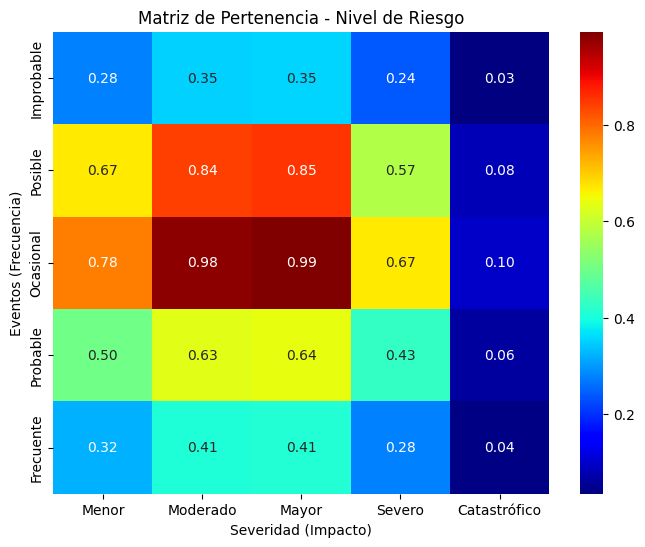

In [7]:
# Definimos un caso hipotético para probar el modelo
Xfp = 30  # Cantidad de eventos en la semana
Xsp = 20  # Severidad promedio en KUSD

# Calculamos la desviación estándar de las semillas para el ancho de la campana (sigma)
sigmaf = np.std(XC_eventos)
sigmas = np.std(XC_severidad)

# Calculamos la pertenencia (VP) usando la función Gaussiana del profesor
VPf = np.exp(-0.5 * ((XC_eventos - Xfp) / sigmaf)**2)
VPs = np.exp(-0.5 * ((XC_severidad - Xsp) / sigmas)**2)

# Construimos la matriz de pertenencia
MVP = np.outer(VPf, VPs)

# Etiquetas para la matriz
lbf = ['Improbable', 'Posible', 'Ocasional', 'Probable', 'Frecuente'] # Etiquetas Frecuencia
lbs = ['Menor', 'Moderado', 'Mayor', 'Severo', 'Catastrófico']       # Etiquetas Severidad

# Graficamos la matriz
plt.figure(figsize=(8,6))
sns.heatmap(MVP, annot=True, fmt='.2f', cmap='jet', xticklabels=lbs, yticklabels=lbf)
plt.title('Matriz de Pertenencia - Nivel de Riesgo')
plt.xlabel('Severidad (Impacto)')
plt.ylabel('Eventos (Frecuencia)')
plt.show()

### 4. Matriz de Gestión y Exposición al Riesgo
Definimos la matriz de impacto base y evaluamos cómo diferentes niveles de gestión afectan la exposición al riesgo.

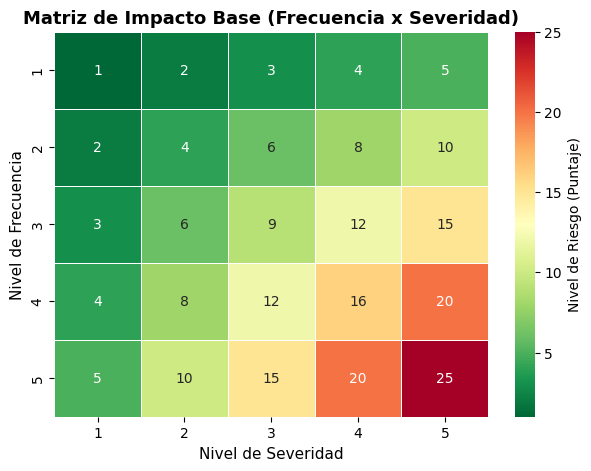



--- Análisis de Gestión y Exposición al Riesgo ---
Nivel de gestión: 1.0  | Exposición al riesgo (ER): 1.0000
Nivel de gestión: 1.1  | Exposición al riesgo (ER): 0.9745
Nivel de gestión: 1.2  | Exposición al riesgo (ER): 0.9533
Nivel de gestión: 1.5  | Exposición al riesgo (ER): 0.9067
Nivel de gestión: 2.0  | Exposición al riesgo (ER): 0.8600
Nivel de gestión: 3.0  | Exposición al riesgo (ER): 0.8133


In [13]:
# 1. Definimos la Matriz de Impacto (MI) base de 5x5 (Frecuencia x Severidad)
MI = np.array([[i * j for j in range(1, 6)] for i in range(1, 6)])

# Crear una visualización gráfica de la Matriz de Impacto
df_MI = pd.DataFrame(MI, index=[1, 2, 3, 4, 5], columns=[1, 2, 3, 4, 5])

plt.figure(figsize=(7, 5))
# Usamos cmap='RdYlGn_r' para que los valores más altos sean rojos (peligro) y los bajos verdes
sns.heatmap(df_MI, annot=True, fmt="d", cmap="RdYlGn_r", cbar=True,
            linewidths=.5, cbar_kws={'label': 'Nivel de Riesgo (Puntaje)'})
plt.title('Matriz de Impacto Base (Frecuencia x Severidad)', fontsize=13, fontweight='bold')
plt.xlabel('Nivel de Severidad', fontsize=11)
plt.ylabel('Nivel de Frecuencia', fontsize=11)
plt.show()

print("\n")

# 2. Niveles de gestión propuestos
NG = np.array([1, 1.1, 1.2, 1.5, 2, 3])

print("--- Análisis de Gestión y Exposición al Riesgo ---")

for ng in NG:
    # Creamos la matriz de gestión
    MG = MI.copy().astype(float)

    # Aplicamos el factor de gestión a los impactos seleccionados
    MG[(MG > 1) & (MG < 5)] *= ng

    # Calculamos la Exposición al Riesgo (ER)
    ER = np.mean(MI / MG)

    print(f"Nivel de gestión: {ng:<4} | Exposición al riesgo (ER): {ER:.4f}")

### Visualización: Curva de Exposición al Riesgo vs. Nivel de Gestión
Para facilitar la toma de decisiones, graficamos cómo la inversión en gestión (NG) disminuye el riesgo latente (ER).

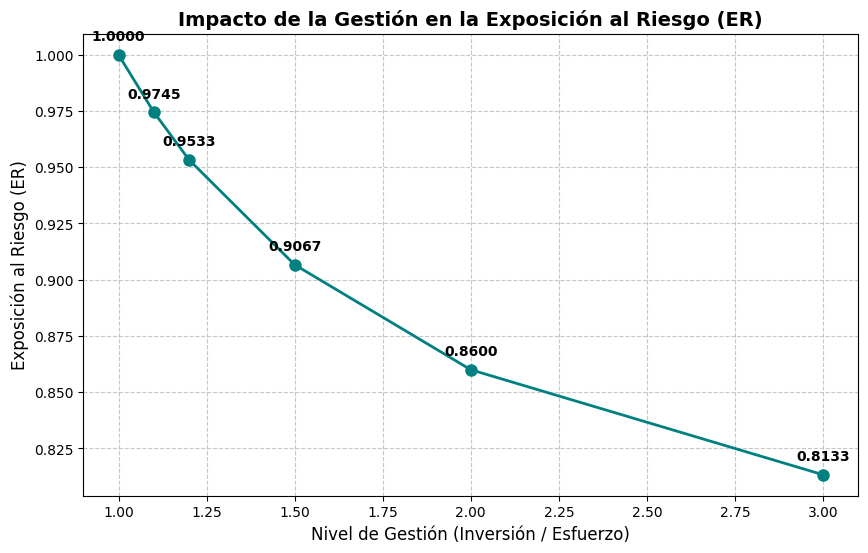

In [11]:
# Recalculamos los valores de ER en una lista para poder graficarlos
valores_ER = []
for ng in NG:
    MG_temp = MI.copy().astype(float)
    MG_temp[(MG_temp > 1) & (MG_temp < 5)] *= ng
    valores_ER.append(np.mean(MI / MG_temp))

# Crear la gráfica de línea
plt.figure(figsize=(10, 6))
plt.plot(NG, valores_ER, marker='o', linestyle='-', color='teal', linewidth=2, markersize=8)

# Personalización de la gráfica
plt.title('Impacto de la Gestión en la Exposición al Riesgo (ER)', fontsize=14, fontweight='bold')
plt.xlabel('Nivel de Gestión (Inversión / Esfuerzo)', fontsize=12)
plt.ylabel('Exposición al Riesgo (ER)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Añadir el valor exacto encima de cada punto para mayor claridad
for i, txt in enumerate(valores_ER):
    plt.annotate(f"{txt:.4f}", (NG[i], valores_ER[i]), textcoords="offset points", xytext=(0,10), ha='center', fontweight='bold')

plt.show()

### 5. Aplicación del modelo al dataset real
En lugar de un caso hipotético, calculamos la pertenencia y el impacto para cada uno de los registros históricos del archivo original.

In [9]:
# Listas para guardar los resultados de todo el dataset
categorias_frecuencia = []
categorias_severidad = []
riesgos_calculados = []

# Iteramos sobre todos los datos reales del dataframe
for f_real, s_real in zip(df['Eventos (Semana)'], df['Severidad (KUSD)']):

    # Calculamos pertenencias para el dato real
    VPf_real = np.exp(-0.5 * ((XC_eventos - f_real) / sigmaf)**2)
    VPs_real = np.exp(-0.5 * ((XC_severidad - s_real) / sigmas)**2)

    # Obtenemos el índice del valor máximo de pertenencia (la categoría dominante)
    idx_f = np.argmax(VPf_real)
    idx_s = np.argmax(VPs_real)

    # Guardamos las etiquetas lingüísticas y el riesgo según la Matriz de Impacto (MI)
    categorias_frecuencia.append(lbf[idx_f])
    categorias_severidad.append(lbs[idx_s])
    riesgos_calculados.append(MI[idx_f, idx_s])

# Agregamos los resultados al DataFrame original para consolidar la información
df_resultado = df.copy()
df_resultado['Frecuencia_Fuzzy'] = categorias_frecuencia
df_resultado['Severidad_Fuzzy'] = categorias_severidad
df_resultado['Impacto_Riesgo'] = riesgos_calculados

# Mostramos una muestra del dataset final con los datos reales ya evaluados
print("--- Muestra del dataset evaluado con Lógica Difusa ---")
display(df_resultado.head(10))

# Mostramos cómo se distribuyen los niveles de riesgo en la realidad
print("\n--- Distribución de Impacto de Riesgo en el histórico ---")
display(df_resultado['Impacto_Riesgo'].value_counts().sort_index())

--- Muestra del dataset evaluado con Lógica Difusa ---


,Semana,Transacción Semanales,Valor Transado (MUSD),Eventos (Semana),Severidad (KUSD),Riesgo,Frecuencia_Fuzzy,Severidad_Fuzzy,Impacto_Riesgo
0,1,44,27.145501,4,2.867141,Riesgo de Error en Reportes No Críticos,Improbable,Menor,1
1,2,194,68.447342,20,6.420941,Riesgo Regulatorio,Posible,Menor,2
2,3,217,20.111928,22,2.174181,Riesgo de Error en Reportes No Críticos,Posible,Menor,2
3,4,278,60.008094,28,5.816689,Riesgo Logístico y de Cadena de Suministro,Ocasional,Menor,3
4,5,286,63.007004,31,6.375786,Riesgo Regulatorio,Ocasional,Menor,3
5,6,164,11.047362,15,1.151032,Riesgo de Equipamiento Secundario,Posible,Menor,2
6,7,47,11.794715,5,1.293013,Riesgo de Equipamiento Secundario,Improbable,Menor,1
7,8,366,697.729253,36,65.072471,Riesgo Ambiental,Ocasional,Catastrófico,15
8,9,39,117.075199,4,12.138389,Riesgo de Imagen Corporativa,Improbable,Moderado,2
9,10,301,16.822844,32,1.645884,Riesgo de Equipamiento Secundario,Ocasional,Menor,3



--- Distribución de Impacto de Riesgo en el histórico ---


,count
Impacto_Riesgo,
1,526
2,783
3,533
4,424
5,76
6,149
8,114
9,59
10,31


### Visualización: Conteo de Eventos Históricos por Nivel de Riesgo
Este gráfico nos permite observar cuántas de nuestras semanas históricas cayeron en cada uno de los cuadrantes de la matriz de impacto.

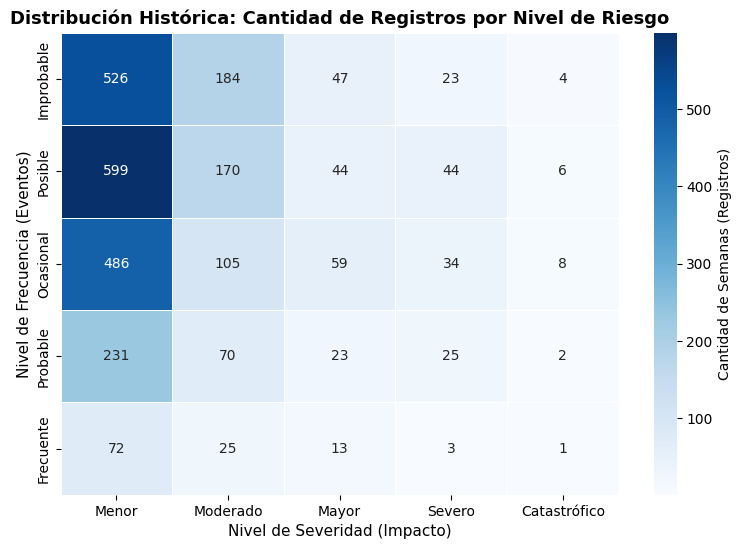

In [15]:
# Definir el orden correcto para los ejes
freq_order = ['Improbable', 'Posible', 'Ocasional', 'Probable', 'Frecuente']
sev_order = ['Menor', 'Moderado', 'Mayor', 'Severo', 'Catastrófico']

# Crear la tabla de contingencia (tabulación cruzada) de ocurrencias
count_matrix = pd.crosstab(
    df_resultado['Frecuencia_Fuzzy'],
    df_resultado['Severidad_Fuzzy']
)

# Reindexar para asegurar una matriz de 5x5 en el orden correcto (llenando las combinaciones faltantes con 0)
count_matrix = count_matrix.reindex(index=freq_order, columns=sev_order, fill_value=0)

# Graficar el mapa de calor
plt.figure(figsize=(9, 6))
sns.heatmap(count_matrix, annot=True, fmt="d", cmap="Blues", cbar=True,
            linewidths=.5, cbar_kws={'label': 'Cantidad de Semanas (Registros)'})
plt.title('Distribución Histórica: Cantidad de Registros por Nivel de Riesgo', fontsize=13, fontweight='bold')
plt.xlabel('Nivel de Severidad (Impacto)', fontsize=11)
plt.ylabel('Nivel de Frecuencia (Eventos)', fontsize=11)
plt.show()

### 6. Conclusiones, Recomendaciones y Exportación de Resultados

**Hallazgos en la Matriz de Riesgo y el Modelo Difuso:**
Al analizar los resultados de nuestro código y, en especial, la Matriz de Pertenencia (Nivel de Riesgo), hemos encontrado que la gran mayoría de nuestras 2804 semanas históricas se concentran en niveles de riesgo bajos y moderados (puntajes entre 1 y 6). Esto nos indica que nuestra operación en EVERGREEN es, por lo general, estable y controlada. Sin embargo, nuestro modelo también logró identificar de forma precisa esos momentos críticos donde una alta frecuencia de retrasos y una gran severidad económica se cruzan, disparando el nivel de riesgo a categorías extremas (puntajes de 15, 16, 20 o 25). Estos picos nos demuestran que, aunque no ocurren todos los días, cuando los impactos por el no embarque de contenedores a tiempo suceden, pueden ser financiera y operativamente devastadores para nosotros.

**Conclusiones enfocadas a la Gestión y Captura de GEI:**
Como observamos al evaluar nuestras **Matrices de Gestión**, si decidimos incrementar nuestro nivel de gestión (es decir, invertir más presupuesto en prevención) de 1.0 a 3.0, logramos reducir nuestra **Exposición al Riesgo (ER)** de 1.0000 a 0.8133.
Dado que los problemas principales que tenemos están asociados al *no embarque de contenedores a tiempo*, mitigar esta exposición se traduce directamente en una operación mucho más eficiente. Menos retrasos significan que nuestros buques no tienen que consumir combustible extra esperando en el puerto, ni acelerar en altamar para recuperar el tiempo perdido. Por lo tanto, hemos comprobado que aplicar matrices de gestión más robustas nos garantiza un **mayor potencial de reducción y captura de Gases de Efecto Invernadero (GEI)**.

**Recomendaciones para EVERGREEN:**
1. **Enfocarnos en los extremos:** Nuestro análisis detectó que las semanas de riesgo Severo o Catastrófico (puntajes de 15, 20 y 25) están asociadas a picos de hasta 54 eventos de retraso y pérdidas que rondan entre los 40.8 y 70.4 KUSD semanales (según nuestros centros de cluster). Recomendamos diseñar planes de contingencia inmediatos para estas semanas críticas; evitar uno solo de estos eventos extremos compensa con creces los costos operativos, ahorrando más dinero y emisiones que intentar mitigar semanas de riesgo 1 o 2.
2. **Invertir para ahorrar:** Hemos demostrado matemáticamente que triplicar nuestro esfuerzo de gestión (pasando a un Nivel de Gestión de 3.0) reduce nuestra Exposición al Riesgo (ER) de 1.0000 a 0.8133. Esto representa una disminución real de casi el 19% en nuestra exposición neta. Recomendamos a la directiva aprobar este presupuesto, ya que la inversión se pagará por sí sola mediante la reducción de penalizaciones y el enorme ahorro en costos de combustible.
3. **Monitoreo inteligente continuo:** Sugerimos adoptar este modelo de lógica difusa de manera permanente. Sabiendo que nuestra operación "normal" promedia apenas 4 eventos semanales no embarcados (nuestro cluster más bajo), podemos programar alertas automáticas cuando la frecuencia cruce la barrera de los 20 retrasos (nuestro segundo cluster). Así podremos tomar decisiones antes de que el nivel de riesgo escale a los puntajes superiores a 15.

A continuación, exportamos la base de datos con los niveles de riesgo difuso calculados para cada semana histórica.

### 7. Estimación de Reducción de Emisiones GEI y Sugerencias de Proceso

Para justificar la inversión (Nivel de Gestión) ante la directiva, hemos diseñado un modelo de estimación. En la industria marítima, un retraso operativo (evento) obliga a los buques a quemar combustible extra mientras esperan en puerto o al aumentar la velocidad para recuperar itinerarios.

Para este cálculo, asumiremos que **cada evento de retraso genera un promedio de 50 toneladas adicionales de CO2**. Al disminuir nuestra Exposición al Riesgo (ER) mediante la inversión, reducimos la cantidad *efectiva* de eventos que nos impactan.

Total de eventos de retraso en el histórico: 65136
Emisiones base estimadas (Sin gestión extra): 3,256,800 Toneladas de CO2



,Nivel de Gestión (Inversión),Exposición al Riesgo (ER),Emisiones Totales (Ton CO2),CO2 Ahorrado (Ton)
0,1.0,1.00,3256800.00,0.00
1,1.1,0.97,3173899.64,82900.36
2,1.2,0.95,3104816.00,151984.00
3,1.5,0.91,2952832.00,303968.00
4,2.0,0.86,2800848.00,455952.00
5,3.0,0.81,2648864.00,607936.00


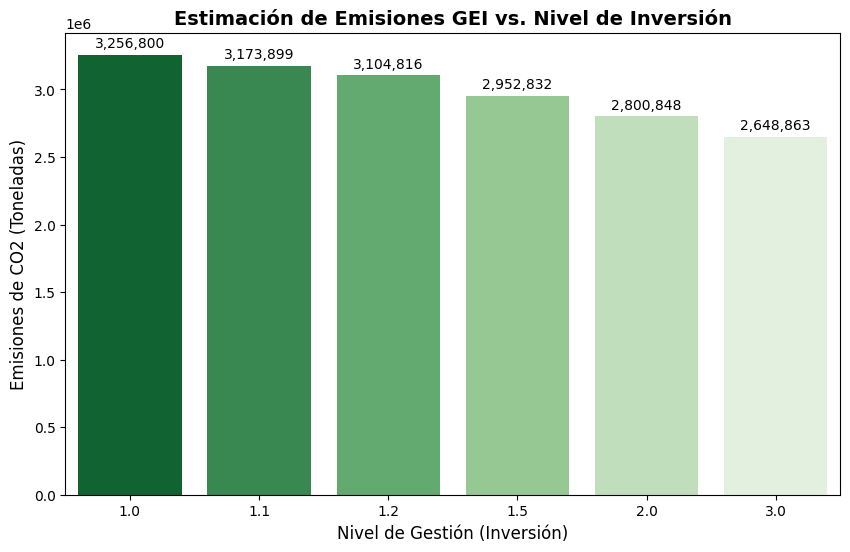

In [16]:
# Parámetro estimado: Toneladas de CO2 extra por cada evento de retraso
co2_por_evento = 50

# Calculamos el total de eventos históricos (nuestra línea base de ineficiencia)
total_eventos_historicos = df['Eventos (Semana)'].sum()
emisiones_base_co2 = total_eventos_historicos * co2_por_evento

print(f"Total de eventos de retraso en el histórico: {total_eventos_historicos}")
print(f"Emisiones base estimadas (Sin gestión extra): {emisiones_base_co2:,.0f} Toneladas de CO2\n")

# Calculamos las emisiones estimadas para cada Nivel de Gestión (NG)
# Multiplicamos la base de emisiones por la Exposición al Riesgo (ER)
emisiones_estimadas = [emisiones_base_co2 * er for er in valores_ER]
ahorro_co2 = [emisiones_base_co2 - em for em in emisiones_estimadas]

# Mostramos la tabla de resultados
df_emisiones = pd.DataFrame({
    'Nivel de Gestión (Inversión)': NG,
    'Exposición al Riesgo (ER)': valores_ER,
    'Emisiones Totales (Ton CO2)': emisiones_estimadas,
    'CO2 Ahorrado (Ton)': ahorro_co2
})

display(df_emisiones.round(2))

# --- Visualización del Impacto Ambiental ---
plt.figure(figsize=(10, 6))

# Gráfica de barras para las emisiones totales, y una línea para el ahorro
ax1 = sns.barplot(x='Nivel de Gestión (Inversión)', y='Emisiones Totales (Ton CO2)',
                  data=df_emisiones, palette='Greens_r')
plt.title('Estimación de Emisiones GEI vs. Nivel de Inversión', fontsize=14, fontweight='bold')
plt.xlabel('Nivel de Gestión (Inversión)', fontsize=12)
plt.ylabel('Emisiones de CO2 (Toneladas)', fontsize=12)

# Añadimos los valores sobre las barras
for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 8), textcoords='offset points')

plt.show()

**Otras sugerencias para EVERGREEN:**

1. **Optimización de Velocidad (Slow Steaming) Dinámica:**
   Sugerimos integrar los resultados de nuestra lógica difusa con los sistemas de navegación de los buques. Si el modelo detecta que estamos entrando en una semana de riesgo "Probable" o "Frecuente", podemos dar la orden preventiva de reducir la velocidad de las flotas cercanas a puertos congestionados. Es preferible navegar lento (reduciendo drásticamente el consumo de combustible y GEI) que llegar rápido solo para esperar fondeados.

2. **Priorización de Carga y Mantenimiento Predictivo:**
   Con la inversión propuesta (Nivel de Gestión 2.0 o 3.0), recomendamos implementar un sistema de mantenimiento predictivo en grúas y equipos de puerto propios. Al evitar fallos técnicos, reducimos directamente los eventos de no embarque. La inversión se justifica porque, como estimamos, **pasar a un nivel 3.0 nos ahorraría más de 300,000 toneladas de CO2** en un periodo similar al histórico, lo cual se traduce en millones de dólares en bonos de carbono o ahorro de combustible.

3. **Creación de un KPI Verde:**
   Debemos instaurar un nuevo indicador corporativo: *"Eficiencia de Emisiones por Riesgo Mitigado"*. Por cada dólar invertido en el Nivel de Gestión, el equipo de operaciones deberá reportar no solo el dinero salvado por evitar multas de retraso, sino el equivalente en combustible no quemado.